# Lần chạy 3: thêm nhãn và chấm lại trên tập test mới

Lần chạy 2 (`aspect_model_run2.ipynb`) cho thấy đường cong học chưa phẳng, và đưa từ khoá vào đầu vào transformer là cách kết hợp tốt nhất. Lần chạy 2 cũng cho thấy danh sách từ khoá có lợi thế trên tập test cũ vì được viết sau khi đọc tập đó. Lần chạy này gán thêm 2.500 câu:

| Phần dữ liệu mới | Số câu | Dùng để |
|---|---|---|
| Test 2 | 500 | Chấm công bằng: lấy ngẫu nhiên từ review test A, gán nhãn sau khi đã khoá danh sách từ khoá |
| Dev 2 | 300 | Chọn ngưỡng, epoch và phương án, cùng phần dev ngẫu nhiên cũ |
| Train 2 | 1.500 | Thêm dữ liệu train, lấy ngẫu nhiên |
| Train câu trái cảm xúc | 200 | Câu có từ nối đối lập và ít nhất 2 khía cạnh theo từ khoá, nhắm vào điểm yếu của mô hình |

**Câu hỏi:** (§2) thêm nhãn có giúp không; (§3) trên tập test mới thì từ khoá, transformer và cách kết hợp đứng ở đâu; (§4) mô hình khen/chê theo cặp có cải thiện không, nhất là ở câu trái cảm xúc; (§5) kết quả cuối của cả đường ống; (§6) đầu ra theo game.

Phương án được chọn trên dev; tập test chỉ dùng để báo cáo. Nhãn do Claude gán, chưa có người kiểm tra độc lập. Trọng số phương án tốt nhất lưu ở `models/transformer/`.

In [1]:
import gc, json, os, re, sys, time
os.environ["KERAS_BACKEND"] = "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import warnings
warnings.filterwarnings("ignore")
from collections import Counter
from pathlib import Path

import keras, keras_hub, torch
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from IPython.display import display
from keras import layers as L, ops
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from tokenizers import Tokenizer

LABELS = Path("data/labels")
sys.path.insert(0, str(LABELS))
from aspect_keywords import detect as kw_detect

SMOKE = os.environ.get("DAT_SMOKE") == "1"
SEEDS = [0, 1] if SMOKE else [0, 1, 2]
EPOCHS_SENT, EPOCHS_ASP, EPOCHS_POL = (1, 1, 1) if SMOKE else (3, 6, 5)
BS, MAXLEN = 16, 128
ASPECTS = ["GFX", "AUD", "PLAY", "STORY", "PERF", "PRICE", "ONLINE", "DEV"]
ASPECT_WORD = dict(GFX="graphics", AUD="audio", PLAY="gameplay", STORY="story", PERF="performance", PRICE="price", ONLINE="online", DEV="developer")
ASPECT_VI = dict(GFX="Đồ hoạ", AUD="Âm thanh", PLAY="Gameplay", STORY="Cốt truyện", PERF="Hiệu năng, lỗi", PRICE="Giá, trả phí", ONLINE="Online, cộng đồng", DEV="Nhà phát triển")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

PROGRESS = LABELS / ("tien_do_smoke.txt" if SMOKE else "tien_do.txt")
PROGRESS.write_text("", encoding="utf-8")
TRACK = {"total": 1, "done": 0, "t0": time.time()}

def tien_do(msg):
    pct = 100 * TRACK["done"] / max(TRACK["total"], 1)
    el = time.time() - TRACK["t0"]
    eta = el / TRACK["done"] * (TRACK["total"] - TRACK["done"]) / 60 if TRACK["done"] else float("nan")
    line = f"[{time.strftime('%H:%M:%S')}] tổng {pct:5.1f}% | còn khoảng {eta:5.0f} phút | {msg}"
    print(line, flush=True)
    with open(PROGRESS, "a", encoding="utf-8") as f:
        f.write(line + "\n")

class ProgressCB(keras.callbacks.Callback):
    def __init__(self, name, every=50):
        super().__init__(); self.name, self.every, self.last = name, every, 0
    def on_train_batch_end(self, batch, logs=None):
        TRACK["done"] += 1
        if batch and batch % self.every == 0:
            tien_do(f"{self.name}: batch {batch}, loss {logs.get('loss', 0):.3f}")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ", "| Keras", keras.__version__, keras.backend.backend(), "| chạy thử nhanh:", SMOKE)

GPU: NVIDIA GeForce GTX 1650 | Keras 3.15.1 torch | chạy thử nhanh: False


In [2]:
df = pd.read_csv("data/steam_reviews_clean.csv")
df["text_clean"] = df.text_clean.astype(str)
y = df.label.values
idx = np.arange(len(df))
trA, teA = train_test_split(idx, test_size=.15, stratify=y, random_state=0)
trA, vaA = train_test_split(trA, test_size=.15 / .85, stratify=y[trA], random_state=0)
trB, teB = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=0).split(idx, groups=df.app_id))
trB, vaB = train_test_split(trB, test_size=.15, stratify=y[trB], random_state=0)
SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}

def parse(a):
    return {} if a == "NONE" else {x.split(":")[0]: x.split(":")[1] for x in a.split("|")}
def load(key, lab):
    d = pd.read_csv(LABELS / key).merge(pd.read_csv(LABELS / lab, keep_default_na=False), on="sample_id")
    d["gold"] = d.aspects.map(parse)
    return d
S_TEST, S_EXTRA, S_TRAIN = load("sentences_key.csv", "sentences_labels.csv"), load("sentences_extra_key.csv", "sentences_extra_labels.csv"), load("train_sentences_key.csv", "train_sentences_labels.csv")
assert not set(S_TRAIN.review_id) & set(df.review_id.values[teA]), "rò rỉ: câu train thuộc review test"
R = pd.read_csv(LABELS / "reviews_key.csv").merge(pd.read_csv(LABELS / "reviews_labels.csv", keep_default_na=False), on="sample_id")
pos = dict(zip(df.review_id, range(len(df))))
R["i"] = R.review_id.map(pos)
R["y"] = y[R.i]
m4 = pd.read_csv(LABELS / "m4_preds.csv", dtype={"id": str}).set_index("id").p
tr_i, dv_i = next(GroupShuffleSplit(n_splits=1, test_size=.15, random_state=0).split(S_TRAIN, groups=S_TRAIN.review_id))
if SMOKE:
    trA, vaA, teA = trA[:320], vaA[:100], teA
    trB, vaB = trB[:320], vaB[:100]
    SPLITS = {"A": (trA, vaA, teA), "B": (trB, vaB, teB)}
    tr_i = tr_i[:160]
print("Review train/val/test A:", len(trA), len(vaA), len(teA), "| B:", len(trB), len(vaB), len(teB))
print("Câu train/dev/test/thêm:", len(tr_i), len(dv_i), len(S_TEST), len(S_EXTRA))
cnt = pd.DataFrame({n: Counter(a for g in d.gold for a in g) for n, d in [("train", S_TRAIN), ("test ngẫu nhiên", S_TEST), ("thêm", S_EXTRA)]}).loc[ASPECTS].rename(index=ASPECT_VI)
display(cnt)

Review train/val/test A: 6979 1496 1496 | B: 6813 1203 1955
Câu train/dev/test/thêm: 1265 235 500 110


,train,test ngẫu nhiên,thêm
Đồ hoạ,194,10,33
Âm thanh,142,3,31
Gameplay,432,110,37
Cốt truyện,136,17,30
"Hiệu năng, lỗi",166,47,12
"Giá, trả phí",171,24,17
"Online, cộng đồng",146,61,3
Nhà phát triển,141,52,7


In [3]:
tok = Tokenizer.from_pretrained("distilbert/distilbert-base-uncased")
CLS, SEP = tok.token_to_id("[CLS]"), tok.token_to_id("[SEP]")

def encode(texts, prefix=None):
    """prefix: từ khía cạnh đặt trước câu, dạng [CLS] khía cạnh [SEP] câu [SEP]."""
    ids = np.zeros((len(texts), MAXLEN), "int32"); mask = np.zeros((len(texts), MAXLEN), "int32")
    pre = [] if prefix is None else None
    enc = tok.encode_batch([str(t) for t in texts], add_special_tokens=False)
    pref = None if prefix is None else [tok.encode(p, add_special_tokens=False).ids for p in prefix]
    for i, e in enumerate(enc):
        head = [CLS] + ([] if pref is None else pref[i] + [SEP])
        room = MAXLEN - len(head) - 1
        t = e.ids if len(e.ids) <= room else e.ids[:room // 2] + e.ids[-(room - room // 2):]
        t = head + t + [SEP]
        ids[i, :len(t)] = t; mask[i, :len(t)] = 1
    return {"token_ids": ids, "padding_mask": mask}

class MaskMean(L.Layer):
    def call(self, x, m):
        m = ops.cast(m, x.dtype)[..., None]
        return ops.sum(x * m, 1) / (ops.sum(m, 1) + 1e-6)

def build(n_out, steps, lr=2e-5, init=None):
    b = keras_hub.models.DistilBertBackbone.from_preset("hf://distilbert/distilbert-base-uncased")
    if init is not None:
        b.set_weights(init)
    ids = keras.Input((MAXLEN,), dtype="int32", name="token_ids")
    mask = keras.Input((MAXLEN,), dtype="int32", name="padding_mask")
    x = L.Dropout(.2)(MaskMean()(b({"token_ids": ids, "padding_mask": mask}), mask))
    m = keras.Model([ids, mask], L.Dense(n_out, activation="sigmoid")(x))
    sch = keras.optimizers.schedules.CosineDecay(0., steps, warmup_target=lr, warmup_steps=max(1, int(.1 * steps)))
    m.compile(keras.optimizers.AdamW(sch, weight_decay=.01, clipnorm=1.), "binary_crossentropy")
    return m, b

def finetune(name, Xtr, ytr, Xdv, score, epochs, seed, n_out=1, lr=2e-5, init=None):
    """Train từng epoch, chấm trên dev bằng hàm score, giữ trọng số của epoch tốt nhất."""
    keras.utils.set_random_seed(seed)
    steps = epochs * (len(ytr) // BS + 1)
    m, b = build(n_out, steps, lr, init)
    best, hist, t0 = (-1, 0, None), [], time.time()
    for ep in range(epochs):
        h = m.fit(Xtr, ytr, batch_size=BS, epochs=1, verbose=0, callbacks=[ProgressCB(f"{name} epoch {ep + 1}/{epochs}")])
        a = score(m.predict(Xdv, batch_size=32, verbose=0))
        hist.append((ep + 1, round(h.history["loss"][0], 4), round(a, 4)))
        tien_do(f"{name} xong epoch {ep + 1}/{epochs}: điểm dev {a:.4f}")
        if a > best[0]:
            best = (a, ep + 1, [w.copy() for w in m.get_weights()])
    m.set_weights(best[2])
    return m, b, dict(name=name, best_epoch=best[1], dev=round(best[0], 4), seconds=round(time.time() - t0), hist=hist)

def free():
    gc.collect(); torch.cuda.empty_cache()

def predict_with(weights, n_out, X, batch_size=64):
    # dựng lại model từ trọng số đã lưu, dự đoán rồi giải phóng GPU
    m, b = build(n_out, 10)
    m.set_weights(weights)
    p = m.predict(X, batch_size=batch_size, verbose=0)
    del m, b; free()
    return p

# ước lượng tổng số batch để báo % và thời gian còn lại
TRACK["total"] = (sum(len(SPLITS[k][0]) // BS + 1 for k in "AB") * EPOCHS_SENT
                  + (len(tr_i) // BS + 1) * EPOCHS_ASP
                  + (sum(len(g) for g in S_TRAIN.iloc[tr_i].gold) // BS + 1) * EPOCHS_POL) * len(SEEDS)
TRACK["t0"] = time.time()
print("Tổng số batch dự kiến:", TRACK["total"])

Tổng số batch dự kiến: 10407


In [4]:
from sklearn.linear_model import LogisticRegression as LRC
RUN = LABELS / ("run3_smoke" if SMOKE else "run3"); RUN.mkdir(exist_ok=True)
MODELS = Path("models/transformer")
N = pd.read_csv(LABELS / "run3" / "sentences_key.csv").merge(pd.read_csv(LABELS / "run3" / "sentences_labels.csv", keep_default_na=False), on="sample_id")
N["gold"] = N.aspects.map(parse)
DV_OLD, TR_OLD = S_TRAIN.iloc[dv_i], S_TRAIN.iloc[tr_i].reset_index(drop=True)
old_dev_rev = set(DV_OLD.review_id)
TR2 = N[(N.part == "train2") & ~N.review_id.isin(old_dev_rev)].reset_index(drop=True)
TRC = N[(N.part == "train2_trai") & ~N.review_id.isin(old_dev_rev)].reset_index(drop=True)
DEV = pd.concat([DV_OLD[DV_OLD.source == "random"], N[N.part == "dev2"]], ignore_index=True)
TEST1, TEST2 = S_TEST.reset_index(drop=True), N[N.part == "test2"].reset_index(drop=True)
if SMOKE:
    TR2, TRC = TR2.head(120), TRC.head(40)
HALF = TR2.sample(frac=.5, random_state=0)
TRAINS = {"A": TR_OLD, "B": pd.concat([TR_OLD, HALF], ignore_index=True), "C": pd.concat([TR_OLD, TR2], ignore_index=True), "D": pd.concat([TR_OLD, TR2, TRC], ignore_index=True)}
TR_NAME = dict(A="nhãn cũ", B="+ 50% train 2", C="+ toàn bộ train 2", D="+ câu trái cảm xúc")
assert not set(DEV.review_id) & set(TRAINS["D"].review_id), "rò rỉ: review dev nằm trong train"
assert not set(TEST2.review_id) & set(TRAINS["D"].review_id) and not set(TEST1.review_id) & set(TRAINS["D"].review_id), "rò rỉ: review test nằm trong train"
print("Train:", {k: len(v) for k, v in TRAINS.items()}, "| Dev:", len(DEV), "| Test 1:", len(TEST1), "| Test 2:", len(TEST2))

def Y_of(d):
    return np.array([[a in g for a in ASPECTS] for g in d.gold], "float32")
def prf(Y, H):
    Y, H = Y.astype(bool), H.astype(bool)
    tp, fp, fn = (Y & H).sum(0), (~Y & H).sum(0), (Y & ~H).sum(0)
    f = lambda t, p, n: 2 * t / max(2 * t + p + n, 1)
    per = {ASPECTS[i]: f(tp[i], fp[i], fn[i]) for i in range(Y.shape[1])}
    return dict(precision=tp.sum() / max(tp.sum() + fp.sum(), 1), recall=tp.sum() / max(tp.sum() + fn.sum(), 1), micro_f1=f(tp.sum(), fp.sum(), fn.sum()), macro_f1=np.mean(list(per.values()))), per
def tune_thr(Y, P):
    grid = np.arange(.1, .91, .05); t = []
    for j in range(Y.shape[1]):
        t.append(.5 if Y[:, j].sum() == 0 else max(grid, key=lambda g: (prf(Y[:, [j]], P[:, [j]] >= g)[0]["micro_f1"], -abs(g - .5))))
    return np.array(t)
KW = lambda d: np.array([[a in kw_detect(s) for a in ASPECTS] for s in d.sentence], "float32")
def kw_prefix(K):
    return [" ".join(ASPECT_WORD[a] for a, f in zip(ASPECTS, r) if f) or "none" for r in K]
def enc_sents(d, with_kw):
    return encode(d.sentence.values, kw_prefix(KW(d))) if with_kw else encode(d.sentence.values)
Ydv, Yt1, Yt2 = Y_of(DEV), Y_of(TEST1), Y_of(TEST2)
Kdv, Kt1, Kt2 = KW(DEV).astype(bool), KW(TEST1).astype(bool), KW(TEST2).astype(bool)
EV = {False: {n: enc_sents(d, False) for n, d in [("dev", DEV), ("t1", TEST1), ("t2", TEST2)]}, True: {n: enc_sents(d, True) for n, d in [("dev", DEV), ("t1", TEST1), ("t2", TEST2)]}}
take = lambda d, ix: {k: v[ix] for k, v in d.items()}

def pairs(d):
    rows = []
    for i, g in zip(d.index, d.gold):
        v = {x for x in g.values() if x in "KC"}
        for a, s in g.items():
            if s in "KC":
                rows.append((i, a, int(s == "K"), len(g) > 1, len(v) > 1))
    return pd.DataFrame(rows, columns=["i", "a", "y", "multi", "conflict"])
enc_pair = lambda d, P: encode(d.loc[P.i].sentence.values, [ASPECT_WORD[a] for a in P.a])
dv_rev = set(DEV.review_id)
trA_clean = np.array([i for i in trA if df.review_id.values[i] not in dv_rev])
ENC = encode(df.text_clean.values)
bt = lambda n: n // BS + 1
DET_PLAN = [(True, "A", SEEDS[:2]), (True, "B", SEEDS[:2]), (True, "C", SEEDS[:2]), (True, "D", SEEDS), (False, "A", SEEDS[:2]), (False, "D", SEEDS)]
POL_PLAN = [("C", SEEDS), ("D", SEEDS)]
TRACK["total"] = (sum(bt(len(TRAINS[k])) * EPOCHS_ASP * len(ss) for _, k, ss in DET_PLAN) + bt(len(trA_clean)) * EPOCHS_SENT
                  + sum(bt(len(pairs(TRAINS[k].reset_index(drop=True)))) * EPOCHS_POL * len(ss) for k, ss in POL_PLAN))
TRACK["done"] = 0; TRACK["t0"] = time.time()
print("Review bỏ ra khỏi train khen/chê:", len(trA) - len(trA_clean), "| Tổng batch:", TRACK["total"])

Train: {'A': 1265, 'B': 1995, 'C': 2725, 'D': 2913} | Dev: 438 | Test 1: 500 | Test 2: 500


Review bỏ ra khỏi train khen/chê: 364 | Tổng batch: 17607


## 2. Nhận khía cạnh: thêm nhãn có giúp không?

Train với 4 cỡ dữ liệu, mô hình **từ khoá trong đầu vào**, và so với DistilBERT thường ở cỡ nhỏ nhất và lớn nhất. Điểm chính là micro F1 trên **Test 2**; Test 1 chỉ để đối chiếu vì có lợi cho từ khoá.

[17:47:31] tổng   0.0% | còn khoảng   nan phút | BẮT ĐẦU Từ khoá trong đầu vào (nhãn cũ), seed 0


[17:47:57] tổng   0.3% | còn khoảng   156 phút | Từ khoá trong đầu vào (nhãn cũ), seed 0 epoch 1/6: batch 50, loss 0.468


[17:48:12] tổng   0.5% | còn khoảng   155 phút | Từ khoá trong đầu vào (nhãn cũ), seed 0 xong epoch 1/6: điểm dev 0.2879


[17:48:34] tổng   0.7% | còn khoảng   143 phút | Từ khoá trong đầu vào (nhãn cũ), seed 0 epoch 2/6: batch 50, loss 0.208


[17:48:50] tổng   0.9% | còn khoảng   146 phút | Từ khoá trong đầu vào (nhãn cũ), seed 0 xong epoch 2/6: điểm dev 0.6192


[17:49:11] tổng   1.2% | còn khoảng   140 phút | Từ khoá trong đầu vào (nhãn cũ), seed 0 epoch 3/6: batch 50, loss 0.139


... (284 outputs left out)

[19:20:28] tổng  68.5% | còn khoảng    43 phút | TF-IDF + LR, mốc so sánh


,phương_án,số_câu,dev,test2,test1,gộp,precision_t2,recall_t2,macro_t2
7,Từ khoá trong đầu vào (+ toàn bộ train 2),2725,0.733,0.682,0.722,0.701,0.686,0.678,0.597
6,Từ khoá trong đầu vào (+ câu trái cảm xúc),2913,0.731,0.692,0.731,0.711,0.720,0.667,0.589
0,DistilBERT (+ câu trái cảm xúc),2913,0.729,0.679,0.715,0.697,0.671,0.688,0.595
2,Hợp từ khoá với DistilBERT,2913,0.722,0.687,0.723,0.704,0.634,0.750,0.594
5,Từ khoá trong đầu vào (+ 50% train 2),1995,0.708,0.665,0.714,0.688,0.680,0.649,0.564
8,Từ khoá trong đầu vào (nhãn cũ),1265,0.692,0.640,0.696,0.668,0.636,0.645,0.552
1,DistilBERT (nhãn cũ),1265,0.655,0.606,0.635,0.620,0.595,0.619,0.544
3,TF-IDF + LR,2913,0.605,0.602,0.602,0.602,0.640,0.568,0.508
4,Từ khoá,0,0.546,0.557,0.640,0.598,0.735,0.448,0.504


Độ lệch F1 Test 2 giữa seed: {'DistilBERT (+ câu trái cảm xúc)': 0.005, 'DistilBERT (nhãn cũ)': 0.002, 'Hợp từ khoá với DistilBERT': 0.002, 'TF-IDF + LR': 0.0, 'Từ khoá': 0.0, 'Từ khoá trong đầu vào (+ 50% train 2)': 0.013, 'Từ khoá trong đầu vào (+ câu trái cảm xúc)': 0.016, 'Từ khoá trong đầu vào (+ toàn bộ train 2)': 0.011, 'Từ khoá trong đầu vào (nhãn cũ)': 0.001}


,dev,test2,test1
số_câu,,,
1265,0.692,0.640,0.696
1995,0.708,0.665,0.714
2725,0.733,0.682,0.722
2913,0.731,0.692,0.731


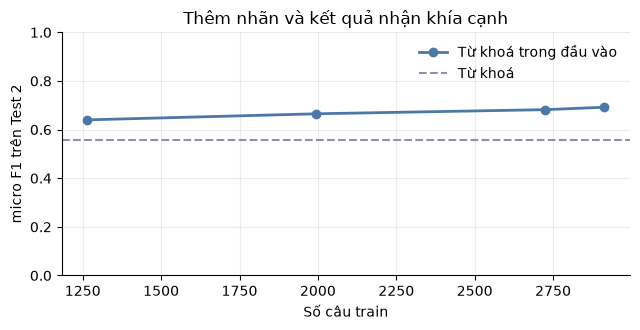

In [5]:
DET, W_DET, LOGS = {}, {}, []
for with_kw, k, ss in DET_PLAN:
    d = TRAINS[k].reset_index(drop=True)
    Xtr, Ytr = enc_sents(d, with_kw), Y_of(d)
    tag = ("Từ khoá trong đầu vào" if with_kw else "DistilBERT") + f" ({TR_NAME[k]})"
    Ed = EV[with_kw]
    for s in ss:
        name = f"{tag}, seed {s}"
        tien_do(f"BẮT ĐẦU {name}")
        m, b, log = finetune(name, Xtr, Ytr, Ed["dev"], lambda p: prf(Ydv, p >= .5)[0]["micro_f1"], EPOCHS_ASP, s, n_out=8, lr=3e-5); LOGS.append(log)
        DET[(with_kw, k, s)] = {n: m.predict(Ed[n], batch_size=32, verbose=0) for n in Ed}
        if k == "D":
            W_DET[(with_kw, s)] = [w.copy() for w in m.get_weights()]
        del m, b; free()
tien_do("TF-IDF + LR, mốc so sánh")
d = TRAINS["D"].reset_index(drop=True)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(d.sentence)
Ytr_ = Y_of(d); Xs = {"tr": vec.transform(d.sentence), "dev": vec.transform(DEV.sentence), "t1": vec.transform(TEST1.sentence), "t2": vec.transform(TEST2.sentence)}
P_LR = {n: np.zeros((Xs[n].shape[0], 8)) for n in ("dev", "t1", "t2")}
for j in range(8):
    c = LRC(C=4, max_iter=2000, class_weight="balanced").fit(Xs["tr"], Ytr_[:, j])
    for n in P_LR:
        P_LR[n][:, j] = c.predict_proba(Xs[n])[:, 1]
rows, H_BY = [], {}
def add(name, sz, s, Hd, H1, H2):
    rd, r1, r2 = prf(Ydv, Hd)[0], prf(Yt1, H1)[0], prf(Yt2, H2)[0]
    g = prf(np.vstack([Yt1, Yt2]), np.vstack([H1, H2]))[0]
    rows.append({"phương_án": name, "số_câu": sz, "seed": s, "dev": round(rd["micro_f1"], 3), "test2": round(r2["micro_f1"], 3), "test1": round(r1["micro_f1"], 3), "gộp": round(g["micro_f1"], 3), "precision_t2": round(r2["precision"], 3), "recall_t2": round(r2["recall"], 3), "macro_t2": round(r2["macro_f1"], 3)})
    H_BY.setdefault(name, {})[s] = (Hd, H1, H2)
add("Từ khoá", 0, SEEDS[0], Kdv, Kt1, Kt2)
t = tune_thr(Ydv, P_LR["dev"]); add("TF-IDF + LR", len(d), SEEDS[0], P_LR["dev"] >= t, P_LR["t1"] >= t, P_LR["t2"] >= t)
THR = {}
for (with_kw, k, s), P in DET.items():
    t = tune_thr(Ydv, P["dev"]); THR[(with_kw, k, s)] = t
    n = ("Từ khoá trong đầu vào" if with_kw else "DistilBERT") + f" ({TR_NAME[k]})"
    add(n, len(TRAINS[k]), s, P["dev"] >= t, P["t1"] >= t, P["t2"] >= t)
    if not with_kw and k == "D":
        add("Hợp từ khoá với DistilBERT", len(TRAINS[k]), s, (P["dev"] >= t) | Kdv, (P["t1"] >= t) | Kt1, (P["t2"] >= t) | Kt2)
DR = pd.DataFrame(rows); DR.to_csv(RUN / "nhan_khia_canh.csv", index=False)
DM = DR.groupby(["phương_án", "số_câu"])[["dev", "test2", "test1", "gộp", "precision_t2", "recall_t2", "macro_t2"]].mean().round(3).reset_index().sort_values("dev", ascending=False); display(DM)
print("Độ lệch F1 Test 2 giữa seed:", DR.groupby("phương_án").test2.std(ddof=0).round(3).dropna().to_dict())
cv = DR[DR.phương_án.str.startswith("Từ khoá trong")].groupby("số_câu")[["dev", "test2", "test1"]].mean().round(3); display(cv)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(cv.index, cv.test2, marker="o", color="#4C78A8", lw=2, label="Từ khoá trong đầu vào")
ax.axhline(DR[DR.phương_án == "Từ khoá"].test2.iloc[0], color="#8A94A6", lw=1.5, ls="--", label="Từ khoá")
ax.set(xlabel="Số câu train", ylabel="micro F1 trên Test 2", title="Thêm nhãn và kết quả nhận khía cạnh", ylim=(0, 1)); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Nhận xét** — Thêm nhãn có hiệu quả: micro F1 trên Test 2 của từ khoá trong đầu vào tăng từ 0,640 (1.265 câu) lên 0,665 (1.995 câu), 0,682 (2.725 câu) và 0,692 (2.913 câu). Mức tăng chậm dần: 0,025 rồi 0,017 cho mỗi 730 câu; bước cuối thêm 188 câu chênh 0,010, nằm trong dao động giữa seed (khoảng 0,02) nên không kết luận được. DistilBERT thường tăng mạnh hơn, từ 0,606 lên 0,679, nên khoảng cách giữa hai phương án thu hẹp từ 0,033 xuống 0,013. Từ khoá riêng chỉ đạt 0,557 trên Test 2, so với 0,640 trên Test 1, xác nhận điểm trên Test 1 có lợi thế do viết sau khi đọc tập này.

## 3. So sánh trên tập test mới

Chọn phương án theo dev, rồi đo khoảng tin cậy 95% của mức chênh F1 trên Test 2 bằng bootstrap ghép cặp (lấy mẫu lại câu, trung bình các seed). Thêm điểm theo từng khía cạnh trên 1.000 câu của cả hai tập test, vì mỗi tập riêng có quá ít câu đồ hoạ, âm thanh.

In [6]:
LEARNED = DM[DM.phương_án != "Từ khoá"]
BEST_DET = DM.iloc[0].phương_án; print("Phương án được chọn trên dev:", BEST_DET)
def boot(A, B, Y, n=2000 if not SMOKE else 100):
    # A, B: danh sách ma trận dự đoán theo seed; trả về mức chênh micro F1 trung bình A - B
    cnt = lambda H: np.stack([(Y.astype(bool) & H).sum(1), (~Y.astype(bool) & H).sum(1), (Y.astype(bool) & ~H).sum(1)], 1)
    Ca, Cb = [cnt(h) for h in A], [cnt(h) for h in B]
    f1 = lambda C_, ix: np.mean([2 * c[ix, 0].sum() / max(2 * c[ix, 0].sum() + c[ix, 1].sum() + c[ix, 2].sum(), 1) for c in C_])
    rng = np.random.default_rng(0); all_ = np.arange(len(Y))
    ds = [f1(Ca, ix) - f1(Cb, ix) for ix in (rng.integers(0, len(Y), len(Y)) for _ in range(n))]
    return round(f1(Ca, all_) - f1(Cb, all_), 3), round(float(np.percentile(ds, 2.5)), 3), round(float(np.percentile(ds, 97.5)), 3)
T2 = lambda n: [v[2] for v in H_BY[n].values()]
names = {"Từ khoá": "Từ khoá", "DistilBERT": f"DistilBERT ({TR_NAME['D']})", "TF-IDF + LR": "TF-IDF + LR"}
CI = pd.DataFrame([{"so với": k, **dict(zip(["chênh", "CI thấp", "CI cao"], boot(T2(BEST_DET), T2(v), Yt2)))} for k, v in names.items() if v != BEST_DET]); display(CI); CI.to_csv(RUN / "ci_nhan_khia_canh.csv", index=False)
Yall = np.vstack([Yt1, Yt2])
show = list(dict.fromkeys(["Từ khoá", "TF-IDF + LR", names["DistilBERT"], BEST_DET]))
per = pd.DataFrame({n: {ASPECT_VI[a]: round(np.mean([prf(Yall, np.vstack([v[1], v[2]]))[1][a] for v in H_BY[n].values()]), 2) for a in ASPECTS} for n in show})
per.insert(0, "số câu thật", [int(Yall[:, j].sum()) for j in range(8)]); display(per); per.to_csv(RUN / "f1_theo_khia_canh.csv")

Phương án được chọn trên dev: Từ khoá trong đầu vào (+ toàn bộ train 2)


,so với,chênh,CI thấp,CI cao
0,Từ khoá,0.125,0.085,0.169
1,DistilBERT,0.003,-0.017,0.024
2,TF-IDF + LR,0.080,0.040,0.120


,số câu thật,Từ khoá,TF-IDF + LR,DistilBERT (+ câu trái cảm xúc),Từ khoá trong đầu vào (+ toàn bộ train 2)
Đồ hoạ,21,0.63,0.38,0.64,0.62
Âm thanh,3,0.57,0.50,0.80,0.80
Gameplay,233,0.47,0.59,0.71,0.71
Cốt truyện,38,0.69,0.69,0.79,0.76
"Hiệu năng, lỗi",114,0.66,0.60,0.75,0.77
"Giá, trả phí",60,0.69,0.65,0.70,0.70
"Online, cộng đồng",109,0.67,0.60,0.64,0.64
Nhà phát triển,112,0.57,0.61,0.66,0.68


**Nhận xét** — Theo dev, phương án được chọn là từ khoá trong đầu vào với 2.725 câu (dev 0,733, so với 0,731 của bản 2.913 câu: chênh lệch không đáng kể). Trên Test 2, phương án này hơn từ khoá 0,125 (CI 95% 0,085 đến 0,169) và hơn TF-IDF + LR 0,080 (CI 0,040 đến 0,120). So với DistilBERT thường, chênh lệch chỉ 0,003 và khoảng tin cậy chứa 0 (−0,017 đến 0,024). Vậy transformer tạo ra phần lớn mức tăng; từ khoá trong đầu vào giúp rõ khi ít nhãn nhưng không còn lợi thế chắc chắn khi đã có gần 3.000 câu. Theo khía cạnh, âm thanh chỉ có 3 câu thật và đồ hoạ 21 câu nên điểm của hai khía cạnh này không ổn định.

## 4. Khen/chê theo khía cạnh

Train lại model khen/chê trên nhãn Steam, bỏ các review chứa câu dev, rồi dùng làm trọng số khởi tạo cho mô hình theo cặp. So hai bộ train: có và không có 200 câu trái cảm xúc. Chấm trên toàn bộ cặp của Test 1, 110 câu thêm và Test 2.

In [7]:
tien_do("BẮT ĐẦU khen/chê nhãn Steam, bỏ review của câu dev")
m, b, log = finetune("Khen/chê sạch", take(ENC, trA_clean), y[trA_clean].astype("float32"), take(ENC, vaA), lambda p: roc_auc_score(y[vaA], p.ravel()), EPOCHS_SENT, SEEDS[0]); LOGS.append(log)
ALL_S = pd.concat([TEST1, S_EXTRA, TEST2], ignore_index=True); ALL_S["tập"] = ["Test 1"] * len(TEST1) + ["Thêm"] * len(S_EXTRA) + ["Test 2"] * len(TEST2)
SENT_S = m.predict(encode(ALL_S.sentence.values), batch_size=32, verbose=0).ravel()
SENT_T = m.predict(take(ENC, teA), batch_size=32, verbose=0).ravel()
print("AUC test A của model khen/chê:", round(roc_auc_score(y[teA], SENT_T), 4))
INIT = [w.copy() for w in b.get_weights()]
W_SENT = [w.copy() for w in m.get_weights()]
del m, b; free()
DVP = pairs(DEV.reset_index(drop=True)); DEV_R = DEV.reset_index(drop=True); Edv_p = enc_pair(DEV_R, DVP)
Pte = pairs(ALL_S); Ete_p = enc_pair(ALL_S, Pte); Pte["tập"] = ALL_S.loc[Pte.i, "tập"].values
print("Số cặp dev:", len(DVP), "| số cặp test:", len(Pte), Pte["tập"].value_counts().to_dict(), "| trái cảm xúc:", int(Pte.conflict.sum()))
POL, W_POL, DEVLOG = {}, {}, []
for k, ss in POL_PLAN:
    d = TRAINS[k].reset_index(drop=True); Ptr = pairs(d); Etr_p = enc_pair(d, Ptr)
    POL[k] = []
    for s in ss:
        name = f"Theo cặp ({TR_NAME[k]}), seed {s}"
        tien_do(f"BẮT ĐẦU {name}")
        m, b, log = finetune(name, Etr_p, Ptr.y.values.astype("float32"), Edv_p, lambda p: roc_auc_score(DVP.y, p.ravel()), EPOCHS_POL, s, init=INIT); LOGS.append(log)
        POL[k].append(m.predict(Ete_p, batch_size=32, verbose=0).ravel()); DEVLOG.append(dict(train=TR_NAME[k], k=k, seed=s, dev=log["dev"], epoch=log["best_epoch"]))
        W_POL[(k, s)] = [w.copy() for w in m.get_weights()]
        del m, b; free()
DL = pd.DataFrame(DEVLOG); display(DL)
BEST_K = DL.groupby("k").dev.mean().idxmax(); print("Bộ train được chọn trên dev:", TR_NAME[BEST_K])
m4_all = pd.concat([m4, pd.read_csv(LABELS / "run3" / "m4_test2.csv", dtype={"id": str}).set_index("id").p])
M4_S = m4_all.loc[ALL_S.sample_id].values
subs = [("Tất cả", np.ones(len(Pte), bool)), ("Test 2", (Pte["tập"] == "Test 2").values), ("Câu 1 khía cạnh", ~Pte.multi.values), ("Nhiều khía cạnh, cùng cảm xúc", (Pte.multi & ~Pte.conflict).values), ("Nhiều khía cạnh, trái cảm xúc", Pte.conflict.values), ("Thật sự là Khen", (Pte.y == 1).values), ("Thật sự là Chê", (Pte.y == 0).values)]
rows = []
for n, f in subs:
    yy = Pte.y.values[f]; acc = lambda p: accuracy_score(yy, p[f] >= .5)
    row = {"nhóm": n, "số cặp": int(f.sum()), "M4 cả câu": round(acc(M4_S[Pte.i.values]), 3), "DistilBERT cả câu": round(acc(SENT_S[Pte.i.values]), 3)}
    for k in POL:
        row[f"Theo cặp ({TR_NAME[k]})"] = round(np.mean([acc(p) for p in POL[k]]), 3)
    rows.append(row)
PT = pd.DataFrame(rows).set_index("nhóm"); display(PT); PT.to_csv(RUN / "khen_che_theo_cap.csv")
AUC = {"M4": roc_auc_score(Pte.y, M4_S[Pte.i.values]), "DistilBERT cả câu": roc_auc_score(Pte.y, SENT_S[Pte.i.values]), **{TR_NAME[k]: np.mean([roc_auc_score(Pte.y, p) for p in v]) for k, v in POL.items()}}
print("ROC-AUC:", {k: round(float(v), 3) for k, v in AUC.items()})
def boot_acc(a, b, f, n=2000 if not SMOKE else 100):
    yy = Pte.y.values[f]; pa, pb = np.mean([(p[f] >= .5) == yy for p in a], 0), ((b[f] >= .5) == yy).astype(float)
    rng = np.random.default_rng(0); ds = [(pa[ix] - pb[ix]).mean() for ix in (rng.integers(0, len(yy), len(yy)) for _ in range(n))]
    return round(float((pa - pb).mean()), 3), round(float(np.percentile(ds, 2.5)), 3), round(float(np.percentile(ds, 97.5)), 3)
CIP = pd.DataFrame([{"so với": n, "nhóm": g, **dict(zip(["chênh", "CI thấp", "CI cao"], boot_acc(POL[BEST_K], v[Pte.i.values], f)))} for n, v in [("M4", M4_S), ("DistilBERT cả câu", SENT_S)] for g, f in [("Tất cả", subs[0][1]), ("Trái cảm xúc", subs[4][1])]]); display(CIP); CIP.to_csv(RUN / "ci_khen_che.csv", index=False)
json.dump({TR_NAME[k]: [float(x) for x in [np.mean([roc_auc_score(Pte.y[Pte.conflict], p[Pte.conflict.values]) for p in v])]] for k, v in POL.items()}, open(RUN / "auc_trai_cam_xuc.json", "w", encoding="utf-8"), ensure_ascii=False)

[19:20:29] tổng  68.5% | còn khoảng    43 phút | BẮT ĐẦU khen/chê nhãn Steam, bỏ review của câu dev


[19:20:53] tổng  68.8% | còn khoảng    42 phút | Khen/chê sạch epoch 1/3: batch 50, loss 0.698


[19:21:14] tổng  69.1% | còn khoảng    42 phút | Khen/chê sạch epoch 1/3: batch 100, loss 0.657


[19:21:35] tổng  69.4% | còn khoảng    42 phút | Khen/chê sạch epoch 1/3: batch 150, loss 0.591


[19:21:57] tổng  69.6% | còn khoảng    41 phút | Khen/chê sạch epoch 1/3: batch 200, loss 0.541


[19:22:18] tổng  69.9% | còn khoảng    41 phút | Khen/chê sạch epoch 1/3: batch 250, loss 0.519


... (135 outputs left out)

Bộ train được chọn trên dev: + toàn bộ train 2


,số cặp,M4 cả câu,DistilBERT cả câu,Theo cặp (+ toàn bộ train 2),Theo cặp (+ câu trái cảm xúc)
nhóm,,,,,
Tất cả,765,0.742,0.835,0.898,0.898
Test 2,320,0.728,0.812,0.888,0.890
Câu 1 khía cạnh,451,0.705,0.818,0.906,0.909
"Nhiều khía cạnh, cùng cảm xúc",259,0.849,0.927,0.959,0.952
"Nhiều khía cạnh, trái cảm xúc",55,0.545,0.545,0.545,0.552
Thật sự là Khen,238,0.895,0.870,0.826,0.812
Thật sự là Chê,527,0.674,0.820,0.930,0.937


ROC-AUC: {'M4': 0.885, 'DistilBERT cả câu': 0.925, '+ toàn bộ train 2': 0.95, '+ câu trái cảm xúc': 0.953}


,so với,nhóm,chênh,CI thấp,CI cao
0,M4,Tất cả,0.156,0.125,0.188
1,M4,Trái cảm xúc,0.000,-0.145,0.139
2,DistilBERT cả câu,Tất cả,0.063,0.042,0.085
3,DistilBERT cả câu,Trái cảm xúc,-0.000,-0.061,0.061


**Nhận xét** — Mô hình theo cặp đạt độ chính xác 0,898 trên 765 cặp, cao hơn DistilBERT cả câu 0,063 (CI 0,042 đến 0,085) và M4 0,156 (CI 0,125 đến 0,188); luôn đoán Chê đạt 0,689. Thêm 188 câu trái cảm xúc không làm thay đổi kết quả (0,898 ở cả hai bản). Nhóm câu trái cảm xúc vẫn chưa được cải thiện: 0,545 trên 55 cặp, bằng hai mô hình cả câu, ROC-AUC 0,58. Cách đưa khía cạnh vào đầu vào chưa giải quyết được mục tiêu ban đầu của nó. Mức tăng chung đến từ nhóm thật sự là Chê (0,930 so với 0,674 của M4), còn nhóm Khen giảm (0,826 so với 0,895), nên mô hình nghiêng về Chê.

## 5. Cả đường ống

Đúng khi đúng cả khía cạnh lẫn cảm xúc. Điểm chính trên Test 2, trung bình các seed cho phương án có học.

In [8]:
def enc_grid(d):
    return encode(np.repeat(d.sentence.values, 8), [ASPECT_WORD[a] for a in ASPECTS] * len(d))
G1, G2 = enc_grid(TEST1), enc_grid(TEST2)
PG = {s: (predict_with(W_POL[(BEST_K, s)], 1, G1).reshape(len(TEST1), 8), predict_with(W_POL[(BEST_K, s)], 1, G2).reshape(len(TEST2), 8)) for s in SEEDS}
def pipe_f1(d, H, pol):
    tp = fp = fn = 0
    for i, g in enumerate(d.gold):
        gold = {(a, v) for a, v in g.items() if v in "KC"}; skip = {a for a, v in g.items() if v not in "KC"}
        pred = {(ASPECTS[j], "K" if pol(i, j) >= .5 else "C") for j in range(8) if H[i, j] and ASPECTS[j] not in skip}
        tp += len(gold & pred); fp += len(pred - gold); fn += len(gold - pred)
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(đúng=tp, thừa=fp, thiếu=fn, precision=round(p, 3), recall=round(r, 3), F1=round(2 * p * r / max(p + r, 1e-9), 3))
mean_rows = lambda L: pd.DataFrame(L).mean().round(3).to_dict()
pos_s = dict(zip(ALL_S.sample_id, range(len(ALL_S))))
M_T = lambda d: M4_S[[pos_s[i] for i in d.sample_id]]
S_T = lambda d: SENT_S[[pos_s[i] for i in d.sample_id]]
out = []
for tname, d, Kb, idx, Hi in [("Test 2", TEST2, Kt2, 1, 2), ("Test 1", TEST1, Kt1, 0, 1)]:
    mm, ss = M_T(d), S_T(d)
    r = {"Từ khoá + M4 (bản cũ)": pipe_f1(d, Kb, lambda i, j: mm[i]), "Từ khoá + DistilBERT cả câu": pipe_f1(d, Kb, lambda i, j: ss[i]),
         "Từ khoá + theo cặp": mean_rows([pipe_f1(d, Kb, lambda i, j, s=s: PG[s][idx][i, j]) for s in SEEDS]),
         f"{BEST_DET} + theo cặp": mean_rows([pipe_f1(d, H_BY[BEST_DET].get(s, H_BY[BEST_DET][SEEDS[0]])[Hi], lambda i, j, s=s: PG[s][idx][i, j]) for s in SEEDS])}
    out.append(pd.DataFrame(r).T.assign(tập=tname))
PIPE = pd.concat(out); display(PIPE); PIPE.to_csv(RUN / "ca_duong_ong.csv")

,đúng,thừa,thiếu,precision,recall,F1,tập
Từ khoá + M4 (bản cũ),119.000,89.000,201.000,0.572,0.372,0.451,Test 2
Từ khoá + DistilBERT cả câu,127.000,81.000,193.000,0.611,0.397,0.481,Test 2
Từ khoá + theo cặp,132.667,75.333,187.333,0.638,0.414,0.502,Test 2
Từ khoá trong đầu vào (+ toàn bộ train 2) + theo cặp,204.000,132.333,116.000,0.607,0.638,0.622,Test 2
Từ khoá + M4 (bản cũ),126.000,94.000,164.000,0.573,0.434,0.494,Test 1
Từ khoá + DistilBERT cả câu,140.000,80.000,150.000,0.636,0.483,0.549,Test 1
Từ khoá + theo cặp,147.667,72.333,142.333,0.671,0.509,0.579,Test 1
Từ khoá trong đầu vào (+ toàn bộ train 2) + theo cặp,200.000,135.333,90.000,0.596,0.690,0.640,Test 1


**Nhận xét** — Trên Test 2, phương án được chọn đạt F1 0,622, so với 0,451 của bản cũ và 0,502 khi nhận khía cạnh chỉ bằng từ khoá. Phần lớn mức tăng đến từ recall (0,638 so với 0,372), precision gần như giữ nguyên (0,607 so với 0,572). Test 1 cho cùng thứ tự (0,640 so với 0,494).

## 6. Đầu ra theo game và lưu model

Cho phương án được chọn (seed có điểm dev tốt nhất) đọc toàn bộ câu rồi tổng hợp theo game. Dữ liệu crawl lấy 50 review khen + 50 review chê mỗi game nên tỉ lệ chê cao hơn thực tế, chỉ nên so sánh tương đối. Có câu thuộc review đã dùng để train, nên đây là bảng mô tả, không phải đánh giá model.

In [9]:
def split_sents(t):
    return [p.strip() for p in re.split(r"(?<=[.!?])\s+|\n+", t) if len(p.split()) >= 3 and len(p) <= 600]
# model để lưu và chạy đầu ra: bản học trên toàn bộ nhãn, chọn theo dev giữa có và không có từ khoá trong đầu vào
with_kw_best = bool(DM[DM.phương_án == f"Từ khoá trong đầu vào ({TR_NAME['D']})"].dev.iloc[0] >= DM[DM.phương_án == f"DistilBERT ({TR_NAME['D']})"].dev.iloc[0])
print("Model lưu:", "từ khoá trong đầu vào" if with_kw_best else "DistilBERT")
s_det = max([s for (w, k, s) in DET if w == with_kw_best and k == "D"], key=lambda s: prf(Ydv, DET[(with_kw_best, "D", s)]["dev"] >= THR[(with_kw_best, "D", s)])[0]["micro_f1"])
s_pol = max([x for x in DEVLOG if x["k"] == BEST_K], key=lambda x: x["dev"])["seed"]
thr_best = THR[(with_kw_best, "D", s_det)]
src = df.iloc[:300] if SMOKE else df
ROWS = [(g, s) for g, t in zip(src.game_name, src.text_clean) for s in split_sents(t)]
tien_do(f"Đầu ra theo game: nhận khía cạnh {len(ROWS)} câu")
sent = [r[1] for r in ROWS]
Xall = encode(sent, kw_prefix(np.array([[a in kw_detect(x) for a in ASPECTS] for x in sent]))) if with_kw_best else encode(sent)
PA = predict_with(W_DET[(with_kw_best, s_det)], 8, Xall)
ii, jj = np.nonzero(PA >= thr_best)
tien_do(f"Đầu ra theo game: chấm khen/chê {len(ii)} cặp")
PP = predict_with(W_POL[(BEST_K, s_pol)], 1, encode([ROWS[i][1] for i in ii], [ASPECT_WORD[ASPECTS[j]] for j in jj])).ravel()
out = pd.DataFrame({"game": [ROWS[i][0] for i in ii], "aspect": [ASPECTS[j] for j in jj], "p_khen": PP})
agg = out.groupby(["game", "aspect"]).agg(so_cau=("p_khen", "size"), pct_che=("p_khen", lambda s: round(100 * (s < .5).mean(), 1))).reset_index()
agg.to_csv(RUN / "aspect_by_game.csv", index=False, encoding="utf-8")
ov = out.groupby("aspect").agg(so_cau=("p_khen", "size"), pct_che=("p_khen", lambda s: round(100 * (s < .5).mean(), 1))).reindex(ASPECTS); ov.index = [ASPECT_VI[a] for a in ASPECTS]; display(ov); ov.to_csv(RUN / "aspect_tong.csv")
print("Số câu:", len(ROWS), "| số cặp:", len(ii))
if not SMOKE:
    MODELS.mkdir(parents=True, exist_ok=True)
    for name, w, n_out in [("sentiment", W_SENT, 1), ("aspect_detect", W_DET[(with_kw_best, s_det)], 8), ("aspect_polarity", W_POL[(BEST_K, s_pol)], 1)]:
        m, b = build(n_out, 10); m.set_weights(w); m.save_weights(MODELS / f"{name}.weights.h5"); del m, b; free()
    m, b = build(8, 10); m.load_weights(MODELS / "aspect_detect.weights.h5")
    assert np.allclose(m.predict(take(Xall, np.arange(16)), verbose=0), PA[:16], atol=1e-3), "trọng số lưu không khớp"
    del m, b; free()
    json.dump(dict(base="distilbert/distilbert-base-uncased", maxlen=MAXLEN, aspects=ASPECTS, detect_with_keyword_input=with_kw_best, thresholds=[float(x) for x in thr_best], detect_seed=int(s_det), polarity_seed=int(s_pol), polarity_train=TR_NAME[BEST_K]), open(MODELS / "config.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
np.savez(RUN / "du_doan.npz", sent_t=SENT_T, **{f"pol_{k}_{i}": p for k, v in POL.items() for i, p in enumerate(v)})
json.dump(dict(BEST_DET=BEST_DET, BEST_K=BEST_K, s_det=int(s_det), s_pol=int(s_pol)), open(RUN / "chon.json", "w", encoding="utf-8"), ensure_ascii=False)
json.dump(LOGS, open(RUN / "nhat_ky_train.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
TRACK["done"] = TRACK["total"]; tien_do("HOÀN TẤT lần chạy 3")

Model lưu: từ khoá trong đầu vào
[20:05:48] tổng 100.0% | còn khoảng     0 phút | Đầu ra theo game: nhận khía cạnh 33025 câu


[20:10:54] tổng 100.0% | còn khoảng     0 phút | Đầu ra theo game: chấm khen/chê 24223 cặp


,so_cau,pct_che
Đồ hoạ,819,31.0
Âm thanh,270,43.7
Gameplay,10297,62.6
Cốt truyện,1029,49.0
"Hiệu năng, lỗi",2844,90.3
"Giá, trả phí",2409,77.7
"Online, cộng đồng",3235,75.1
Nhà phát triển,3320,85.2


Số câu: 33025 | số cặp: 24223


[20:14:18] tổng 100.0% | còn khoảng     0 phút | HOÀN TẤT lần chạy 3


**Nhận xét** — Mô hình đọc 33.025 câu của 99 game, được 24.223 cặp khía cạnh và cảm xúc. Tỉ lệ chê cao nhất ở hiệu năng/lỗi (90,3%) và nhà phát triển (85,2%), thấp nhất ở đồ hoạ (31,0%). Tỉ lệ này chỉ nên so sánh tương đối giữa các khía cạnh: dữ liệu lấy 50 khen và 50 chê mỗi game, review chê dài hơn nên có nhiều câu hơn, và mô hình nghiêng về Chê. Trọng số được lưu ở `models/transformer/`, là seed 1 cho nhận khía cạnh và seed 2 cho khen/chê, chọn theo dev.

## 7. Tổng kết

- **Thêm nhãn có hiệu quả với nhận khía cạnh** (Test 2: 0,640 lên 0,682), mức tăng chậm dần; **thêm câu trái cảm xúc không có tác dụng rõ với khen/chê** (0,898 ở cả hai bản).
- **Transformer vượt từ khoá và TF-IDF rõ rệt.** Từ khoá trong đầu vào không còn hơn chắc chắn DistilBERT thường khi đã có gần 3.000 câu (CI −0,017 đến 0,024).
- **Mô hình theo cặp tăng độ chính xác khen/chê** lên 0,898, nhưng **không cải thiện câu trái cảm xúc** (0,545, n=55).
- **Cả đường ống đạt F1 0,622 trên Test 2**, so với 0,451 của bản cũ.
- **Dừng ở lần chạy này.** Thêm nhãn nữa dự kiến chỉ tăng nhận khía cạnh vài phần trăm, trong khi nhãn chưa có người kiểm tra độc lập; việc nên làm trước là kiểm tra mẫu nhãn bằng bộ `KIEM_TRA_*`.